# Collision-condition missingness and coding consistency

## tl;dr
The rebuilt 1999–2021 event release supports **qualified descriptive condition comparisons for 2012–2021**. Unknown information is generally limited, but Q/QQ residual categories and joint missingness matter. Requiring all nine named condition fields retains only **75.79% of 2021 tractor events**. An early 1999–2000 configuration distribution shift needs qualification.

This notebook audits availability and coding; it does not estimate weather effects, fault, causal factors or driving risk.

## Context & Methods

One row per collision, including every positively recorded tractor event. We compare tractor events with their no-recorded-tractor complement, not a car-only population. Observed/strict and fatal/injury strata remain separate. The supplied dictionary's field-specific code domains distinguish Q/QQ other, U/UU unknown, X/XX not provided, derived conflict nulls and invalid values. No imputation or source rewriting occurs.

### Key assumptions
Valid syntax is not proof of invariant historical coding. Annual frequency-shift flags are diagnostic: absolute unavailable-rate change ≥2 percentage points or total variation ≥0.15. They do not identify causes or test statistical significance. Retaining Q/QQ is different from requiring named categories. Event fields cannot identify measured darkness, jurisdiction, vehicle manoeuvres or fault.

Methods: `docs/conditions_quality.md`; input/code/dictionary fingerprints: `reports/conditions_quality/summary.json`.

In [1]:
from pathlib import Path
import csv, json, sys
from IPython.display import display, HTML, Image
import duckdb
root=Path.cwd()
if not (root/'pyproject.toml').exists(): root=root.parent
sys.path.insert(0,str(root/'src'))
from truck_collisions.audit_conditions import audit
from truck_collisions.build import quote
summary=audit(root)
output=root/'reports/conditions_quality'
def read(name):
    with (output/name).open(newline='') as stream:return list(csv.DictReader(stream))
def show(rows,columns):
    from html import escape
    display(HTML('<table><thead><tr>'+''.join('<th>'+escape(c)+'</th>' for c in columns)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows)+'</tbody></table>'))
profiles=read('annual_field_quality.csv')
joint=read('joint_field_coverage.csv')
book=json.loads((root/'data/reference/collision_codebook.json').read_text())['fields']
connection=duckdb.connect()
connection.execute(f"CREATE VIEW events AS SELECT * FROM read_parquet({quote(root/'data/derived/ncdb/collisions.parquet')})")
connection.execute(f"CREATE VIEW conflicts AS SELECT * FROM read_parquet({quote(root/'data/derived/ncdb/collision_attribute_conflicts.parquet')})")
assert len(profiles)==23*3*2*3*11
assert len(joint)==23*3*2*3*4
print('Coverage:23years,11fields,3cohorts,2subsets,3severity strata')

{
  "annual_field_rows": 4554,
  "joint_coverage_rows": 1656,
  "unexpected_codes": [
    {
      "year": 2020,
      "source_id": "ncdb_2020_official",
      "cohort": "all_events",
      "subset": "observed",
      "severity": "all",
      "field": "C_VEHS",
      "code": "**",
      "status": "unexpected",
      "code_events": 1,
      "events": 79990,
      "pct": 0.0012501562695336917
    }
  ],
  "flagged_tractor_transitions": [
    {
      "year": 2000,
      "cohort": "tractor",
      "field": "C_CONF",
      "unavailable_change_pp": -1.7081923529122665,
      "other_change_pp": 1.906105412548527,
      "total_variation": 0.21788614310108378,
      "source_id_changed": false,
      "review_flag": true
    },
    {
      "year": 2000,
      "cohort": "tractor",
      "field": "C_RCFG",
      "unavailable_change_pp": -3.5013825188841015,
      "other_change_pp": -0.477266928142007,
      "total_variation": 0.04739242418700017,
      "source_id_changed": false,
      "review_flag"

## Data
### Independently recompute the 253 primary tractor field/year profiles
The following queries operate directly on event columns, using SQL predicates rather than the audit's long-table classifier. Source conflict nulls are checked through the conflict export. Dictionary transcription itself remains a documented reference assumption.

In [2]:
def quoted(value):return "'"+str(value).replace("'","''")+"'"
primary={(int(r['year']),r['field']):r for r in profiles if r['cohort']=='tractor' and r['subset']=='observed' and r['severity']=='all'}
checked=0
for field,spec in book.items():
    def inside(values):
        return f"e.{field} IN ("+','.join(quoted(v) for v in values)+')' if values else 'FALSE'
    top=spec['top_coded_codes']
    conditions={
        'defined':inside([v for v in spec['defined_codes'] if v not in top]),
        'top_coded':inside(top),
        'other':inside(spec['other_codes']),
        'unknown':inside(spec['unknown_codes']),
        'not_provided':inside(spec['not_provided_codes']),
        'not_applicable':inside(spec['not_applicable_codes']),
        'conflict_null':f"e.{field} IS NULL AND c.field IS NOT NULL",
        'null_or_blank':f"(e.{field} IS NULL OR trim(e.{field})='') AND c.field IS NULL",
    }
    allowed=[*spec['defined_codes'],*spec['other_codes'],*spec['unknown_codes'],*spec['not_provided_codes'],*spec['not_applicable_codes']]
    conditions['unexpected']=f"e.{field} IS NOT NULL AND trim(e.{field})<>'' AND NOT ("+inside(allowed)+')'
    expressions=','.join(f'count(*) FILTER(WHERE {condition})' for condition in conditions.values())
    query=f"SELECT e.C_YEAR,count(*),{expressions} FROM events e LEFT JOIN conflicts c ON e.source_id=c.source_id AND e.C_YEAR=try_cast(c.C_YEAR AS INTEGER) AND e.C_CASE=c.C_CASE AND c.field={quoted(field)} WHERE e.is_road_tractor GROUP BY e.C_YEAR"
    for values in connection.execute(query).fetchall():
        row=primary[(values[0],field)]
        assert int(row['events'])==values[1]
        for status,count in zip(conditions,values[2:]):assert int(row[status+'_events'])==count,(field,values[0],status)
        checked+=1
assert checked==253
print('Direct-event SQL reproduced253 field/year profiles and all9 status counts in each.')

Direct-event SQL reproduced253 field/year profiles and all9 status counts in each.


In [3]:
statuses=['defined','top_coded','other','unknown','not_provided','not_applicable','null_or_blank','conflict_null','unexpected']
idx={(int(r['year']),r['cohort'],r['subset'],r['severity'],r['field']):r for r in profiles}
metrics=['events',*[s+'_events' for s in statuses]]
for key,row in idx.items():
    year,cohort,subset,severity,field=key
    assert sum(int(row[s+'_events']) for s in statuses)==int(row['events'])
    if cohort=='all_events':
        for metric in metrics:assert int(row[metric])==sum(int(idx[(year,c,subset,severity,field)][metric]) for c in ('tractor','no_recorded_tractor'))
    if severity=='all':
        for metric in metrics:assert int(row[metric])==sum(int(idx[(year,cohort,subset,s,field)][metric]) for s in ('fatal','injury'))
print('All4554 profiles:status partition,cohort complement,andseverity additivity passed.')

All4554 profiles:status partition,cohort complement,andseverity additivity passed.


## Results
### Recent field availability
Unknown/unavailable/invalid and valid Q/QQ other remain separate. Values below use all 2,276 observed tractor events in 2021 as the denominator.

field,events,unavailable_pct,other_pct
Weather,2276,0.97,0.22
Road surface,2276,0.35,4.79
Crash configuration,2276,1.54,5.93
Road configuration,2276,5.32,3.95
Hour,2276,0.62,0.00
Month,2276,0.00,0.00
Weekday,2276,0.00,0.00
Road alignment,2276,2.64,0.00
Traffic control,2276,2.59,2.20


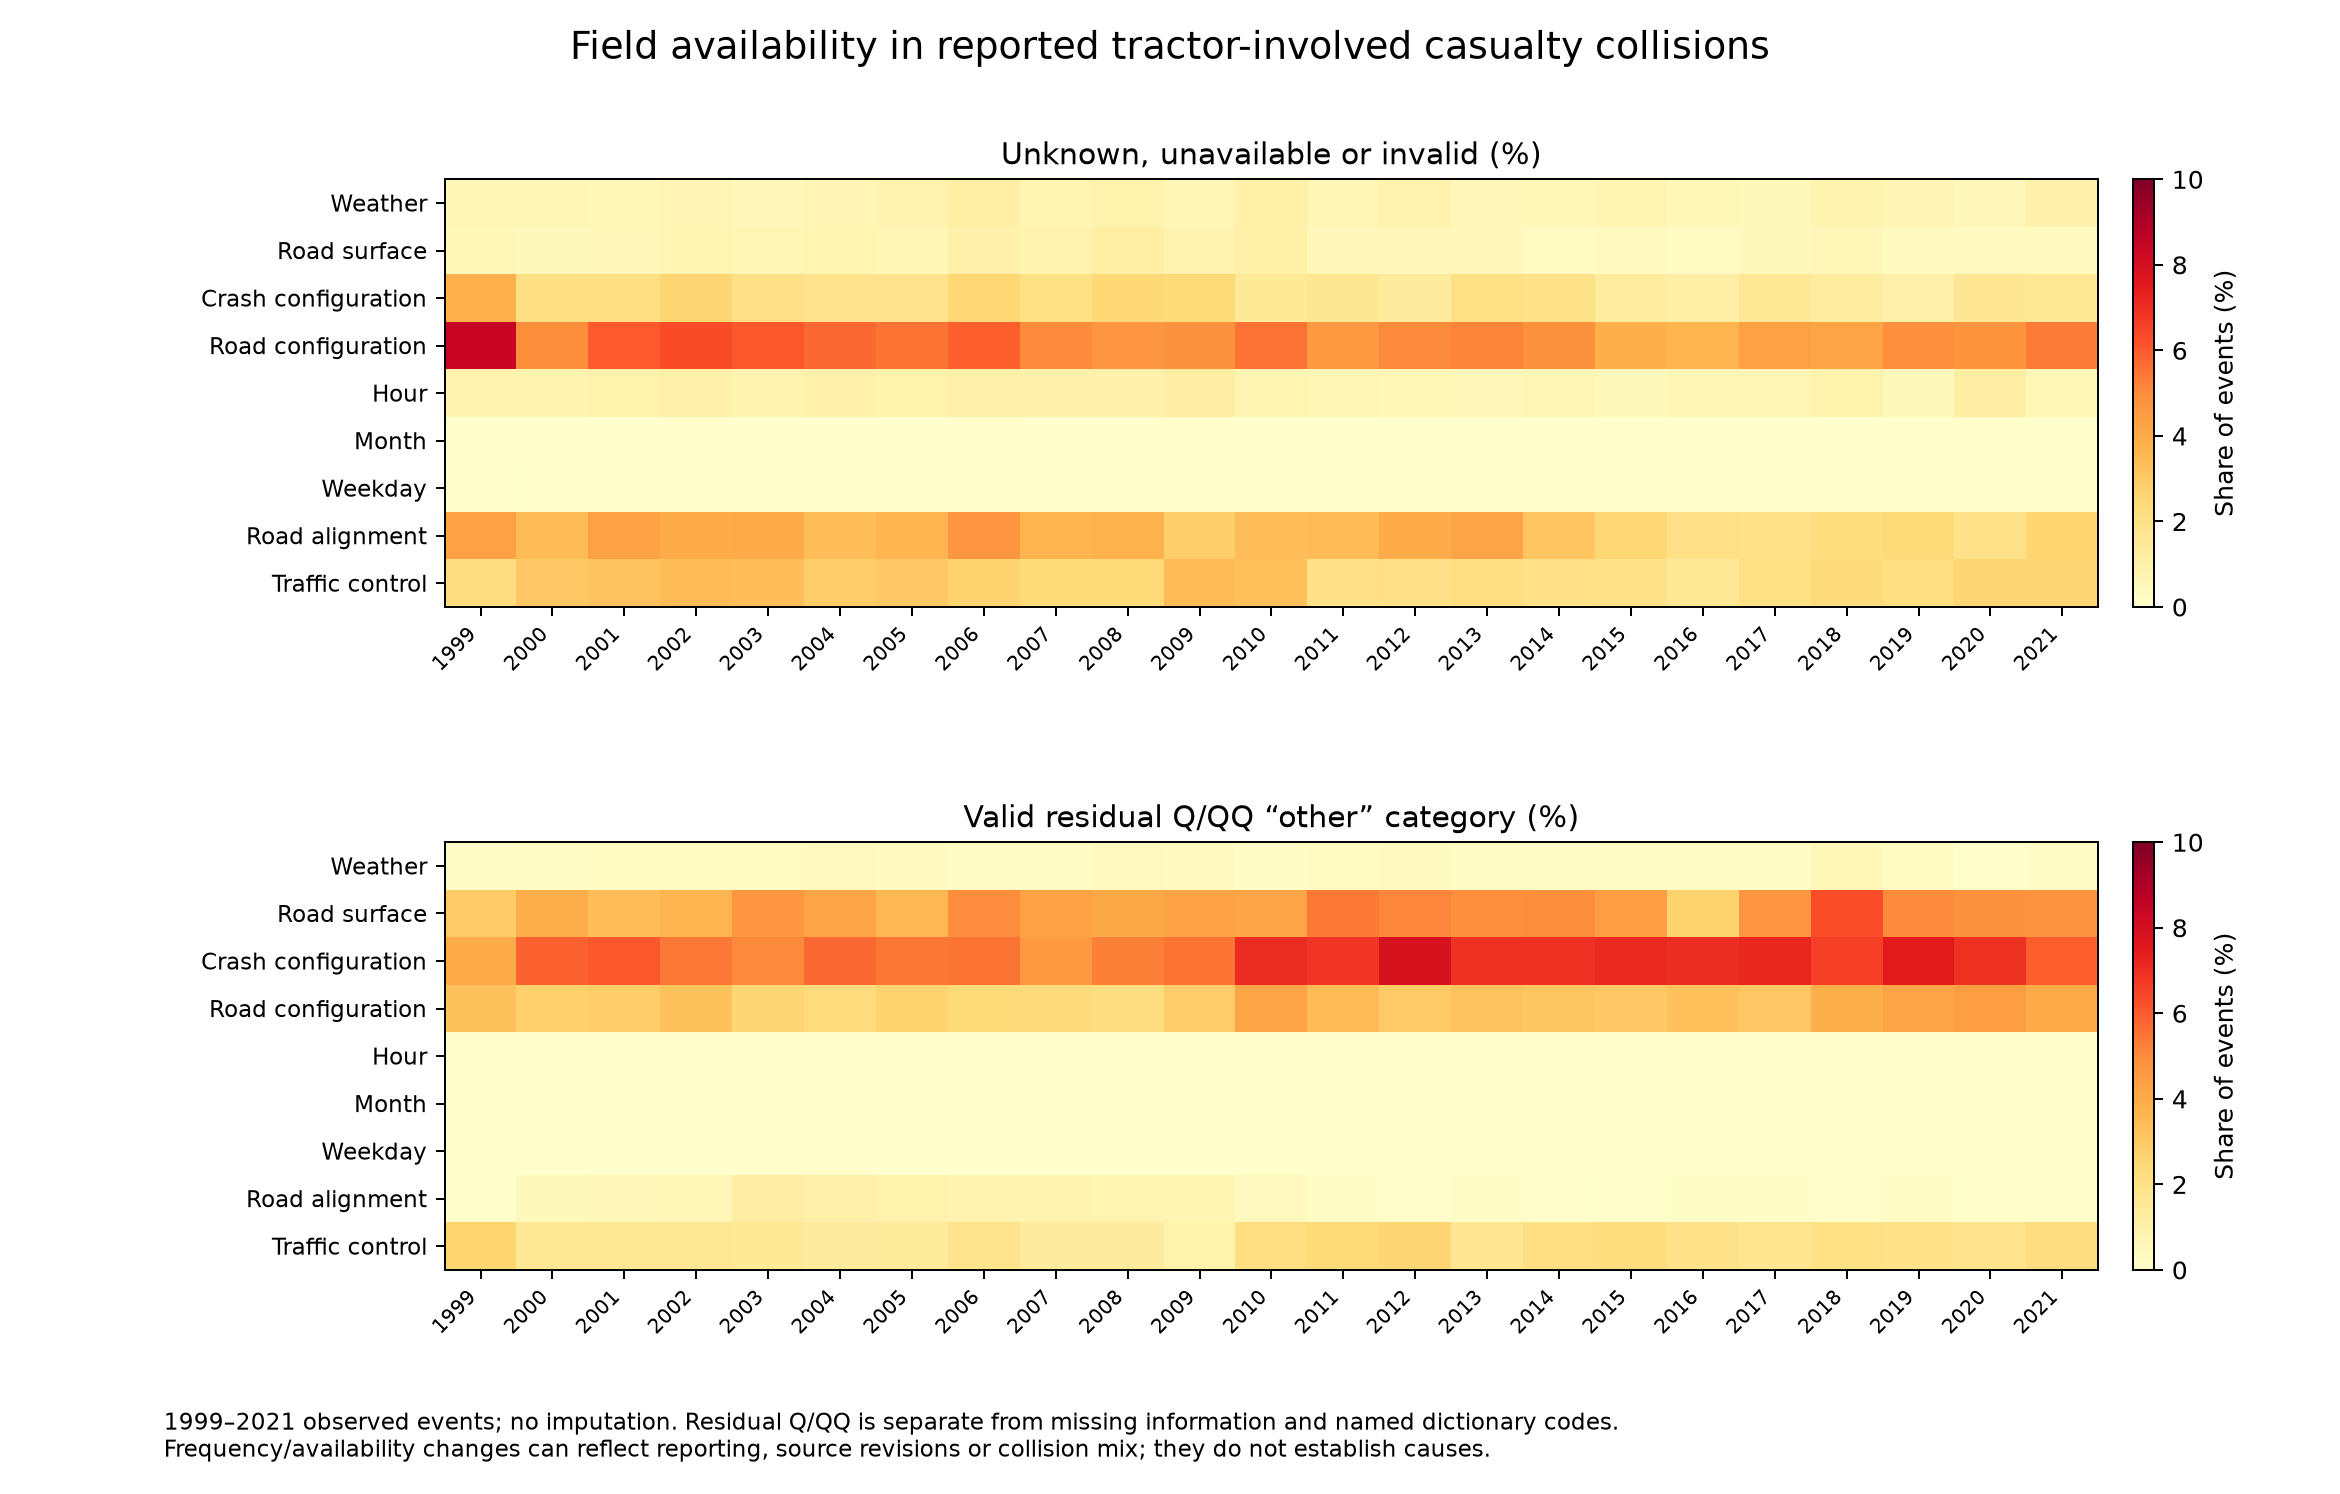

In [4]:
selected=['C_WTHR','C_RSUR','C_CONF','C_RCFG','C_HOUR','C_MNTH','C_WDAY','C_RALN','C_TRAF']
rows=[{'field':book[f]['label'],'events':primary[(2021,f)]['events'],'unavailable_pct':f"{float(primary[(2021,f)]['unavailable_pct']):.2f}",'other_pct':f"{float(primary[(2021,f)]['other_pct']):.2f}"} for f in selected]
show(rows,['field','events','unavailable_pct','other_pct'])
display(Image(filename=str(output/'field_availability.png')))

### Joint-field availability and sample selection
Independently verify 2021 tractor retained counts for all four bundles with direct event predicates. The table also shows 2012 and severity-specific 2021 coverage. These are retained-event counts, not evidence that complete cases are representative.

In [5]:
recent=[r for r in joint if r['year']=='2021' and r['cohort']=='tractor' and r['subset']=='observed' and r['severity']=='all']
for row in recent:
    fields=row['fields'].split('|')
    def required(include_other):
        conditions=[]
        for field in fields:
            values=list(book[field]['defined_codes'])+(book[field]['other_codes'] if include_other else [])
            conditions.append('coalesce('+field+' IN ('+','.join(quoted(v) for v in values)+'),false)')
        return ' AND '.join(conditions)
    for include_other,metric in [(False,'named_complete_events'),(True,'available_including_other_events')]:
        count=connection.execute('SELECT count(*) FROM events WHERE is_road_tractor AND C_YEAR=2021 AND '+required(include_other)).fetchone()[0]
        assert count==int(row[metric])
show([r for r in joint if r['year'] in ('2012','2021') and r['cohort']=='tractor' and r['subset']=='observed' and r['severity']=='all'],['year','bundle','events','named_complete_events','available_including_other_events','named_complete_pct'])
all_nine=next(r for r in recent if r['bundle']=='all_planned_conditions')
print('2021events excluded by all-nine named requirement:',int(all_nine['events'])-int(all_nine['named_complete_events']))

year,bundle,events,named_complete_events,available_including_other_events,named_complete_pct
2012,all_planned_conditions,3300,2470,2962,74.84848484848484
2012,configuration_road,3300,2763,3097,83.72727272727273
2012,core_conditions_time,3300,2586,3055,78.36363636363636
2012,weather_surface,3300,3095,3268,93.78787878787878
2021,all_planned_conditions,2276,1725,2009,75.7908611599297
2021,configuration_road,2276,1918,2123,84.27065026362038
2021,core_conditions_time,2276,1793,2086,78.77855887521969
2021,weather_surface,2276,2138,2251,93.93673110720562


2021events excluded by all-nine named requirement: 551


### Unexpected codes, cohort gaps and temporal flags
The one unexpected event code is the previously documented 2020 vehicle count `**`; the three derived conflict nulls remain separately classified. No condition field has an unexpected code. Flagged frequency changes require interpretation rather than automatic recoding.

In [6]:
show(summary['unexpected_codes'],['year','field','code','code_events','events'])
assert all(r['field']=='C_VEHS' for r in summary['unexpected_codes'])
flags=[r for r in read('annual_distribution_changes.csv') if r['cohort']=='tractor' and r['review_flag']=='True']
show(flags,['year','field','unavailable_change_pp','total_variation'])
assert not any(int(r['year'])>=2012 for r in flags)
show([r for r in read('cohort_quality_gaps.csv') if r['year']=='2021' and r['field'] in ('C_WTHR','C_RSUR','C_CONF','C_RCFG','C_HOUR')],['field','tractor_unavailable_pct','comparator_unavailable_pct','tractor_other_pct','comparator_other_pct'])
connection.close()

year,field,code,code_events,events
2020,C_VEHS,**,1,79990


year,field,unavailable_change_pp,total_variation
2000,C_CONF,-1.7081923529122665,0.21788614310108378
2000,C_RCFG,-3.5013825188841015,0.04739242418700017


field,tractor_unavailable_pct,comparator_unavailable_pct,tractor_other_pct,comparator_other_pct
C_CONF,1.5377855887521967,4.023907322232334,5.931458699472759,5.64478441596773
C_HOUR,0.6151142355008787,0.8989841847652311,0.0,0.0
C_RCFG,5.31634446397188,6.140394028088644,3.9543057996485063,4.683080404358413
C_RSUR,0.351493848857645,1.0650072558231054,4.789103690685413,2.822392207983865
C_WTHR,0.9666080843585237,1.5864426789974666,0.21968365553602812,0.15372506579432815


## Takeaways

- Proceed with qualified descriptive 2012–2021 comparisons using field-specific all-event denominators and explicit unknown and Q/QQ categories. Use conditional known-value tables as labelled sensitivities.
- Avoid silently restricting every question to a single all-nine-field complete-case dataset: it removes 24.21% of 2021 tractor events.
- The 1999–2000 configuration shift warrants qualification before long-history pooling; a distribution shift does not prove a coding change. No 2012–2021 tractor transition triggers the stated review thresholds, which is not proof of invariant semantics.
- Hour is not darkness; road configuration is not a full road-class variable; crash configuration is not vehicle manoeuvre or fault. Exposure and causal conclusions require additional evidence.
- This audit changes no production data and does not perform weather/configuration outcome comparisons. The full assessment and next-step rules are in `docs/conditions_quality.md`.